# Lab: Clinical Decision Support — Heart Disease Referral Alerting

**Syllabus tie-in:** Unit II — AI Applications Across the Healthcare Ecosystem — *Clinical Decision Support Systems*

**Objective:** Practice, on your own, the same steps you used in the Week 2 diabetes lab — exploratory data analysis, data cleaning, normalization, model training, and evaluation — this time on a new dataset with a new twist: encoding categorical clinical codes, and treating the **alert threshold as a clinical decision**, not a modeling default.

**How this notebook works:** This is a **practice lab, not a worked tutorial**. Each section explains a concept and tells you what to produce; the code cells are for you to fill in. Refer back to the diabetes notebook and lecture material for the *how* — this lab is where you apply it yourself. A separate solution notebook exists for you to check your work against **after** you've made a genuine attempt — don't open it first.

**Important framing before we start:** This model is a **teaching exercise on a public research dataset**, not a validated clinical tool. Nothing it outputs should be read as a diagnosis. We are practicing the *mechanics* of building a decision-support alert — the much harder problem of proving one is safe to deploy is Unit IV/V territory.


Run the cell below as-is — it just loads the libraries you'll need. You used all of these in the diabetes lab except `precision_recall_curve`, which you'll use in Section 5.


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve, roc_auc_score,
    precision_recall_curve
)

plt.style.use('seaborn-v0_8-whitegrid')


## 1. The Clinical Scenario and the Dataset

**Scenario:** A general physician sees patients for routine checkups. Some non-invasive tests are already collected (age, blood pressure, cholesterol, resting ECG, an exercise stress test). The clinic wants a simple tool that flags which patients should be referred to a cardiologist for further (invasive) evaluation — rather than referring everyone, or relying only on physician judgement, which varies.

**Dataset:** UCI **Heart Disease (Cleveland)** dataset — 303 patients, 13 clinical attributes, collected at the Cleveland Clinic Foundation. This is one of the most widely used datasets in clinical ML research.

| Column | Meaning |
|---|---|
| age | Age in years |
| sex | 1 = male, 0 = female |
| cp | Chest pain type (1: typical angina, 2: atypical angina, 3: non-anginal pain, 4: asymptomatic) |
| trestbps | Resting blood pressure (mm Hg) |
| chol | Serum cholesterol (mg/dl) |
| fbs | Fasting blood sugar > 120 mg/dl (1 = true, 0 = false) |
| restecg | Resting ECG results (0: normal, 1: ST-T abnormality, 2: probable/definite left ventricular hypertrophy) |
| thalach | Maximum heart rate achieved (exercise stress test) |
| exang | Exercise-induced angina (1 = yes, 0 = no) |
| oldpeak | ST depression induced by exercise relative to rest |
| slope | Slope of the peak exercise ST segment (1: upsloping, 2: flat, 3: downsloping) |
| ca | Number of major vessels (0–3) colored by fluoroscopy |
| thal | 3 = normal, 6 = fixed defect, 7 = reversible defect |
| target | Angiographic disease status: 0 = no disease, 1–4 = disease present (increasing severity) |

We'll binarize `target` into "disease present" (1) vs. "no disease" (0), which is the standard approach for this dataset — the severity grades (1–4) are not reliably distinguishable from these 13 features alone.


In [23]:
url = "https://raw.githubusercontent.com/AndreasPr/Heart-Disease-Prediction-System/master/processed.cleveland.data.csv"

columns = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]

# '?' marks missing values in the original UCI file
df = pd.read_csv(url, names=columns, na_values="?")

# Binarize target: 0 = no disease, 1 = disease present (any severity)
df["target"] = (df["target"] > 0).astype(int)

print("First 5 rows:")
df.head()


First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [24]:
print(f"Number of patients: {len(df)}")
print(f"Number of features: {df.shape[1] - 1}")


Number of patients: 303
Number of features: 13


## 2. Exploratory Data Analysis

### 2.1. Missing Values

Unlike the diabetes dataset, missingness here is **explicit** (`?` in the source file, already converted to `NaN` when we loaded the data) rather than disguised as biologically-impossible zeros.

**Your task:**
1. Print how many missing values each column has.
2. You should find missing values in exactly two columns. Both are effectively categorical/ordinal with only a handful of possible values — think about why the *mean* (your default from the diabetes lab) would produce a nonsensical value here, and impute with the **mode** instead.


In [25]:
# Count missing values in each column
missing_counts = df.isna().sum()
print("Missing values per column:")
print(missing_counts)


Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


In [26]:
# Impute the categorical/ordinal columns with their modes
for col in ["ca", "thal"]:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after imputation:")
print(df.isna().sum())


Missing values after imputation:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


### 2.2. Encoding Categorical Features

This is new compared to the diabetes lab: several columns here are **categorical codes**, not continuous measurements, even though they're stored as numbers:

- `cp`, `restecg`, `slope`, `thal` are **nominal** (the numeric codes have no inherent order) — these need one-hot encoding, or a model like logistic regression will wrongly treat e.g. `thal=7` as "more" of something than `thal=3`.
- `sex`, `fbs`, `exang` are already binary (0/1) — no change needed.
- `ca` is a genuine count (0–3 vessels) — leave it numeric since more vessels affected is meaningfully "more."

**Your task:**
1. One-hot encode the four nominal columns listed above (`pd.get_dummies` is your friend, same as you may have used for categorical features before — check the pandas documentation if this is new to you).
2. Store the result in a new dataframe, e.g. `df_encoded`.
3. **Tip:** the nominal columns loaded as decimals (e.g. `3.0` not `3`). If you one-hot encode them as-is, you'll get messy column names like `cp_2.0`. Consider converting those columns to integer type *before* encoding.


In [27]:
# Cast coded categorical/binary columns to integers before one-hot encoding
coded_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
for col in coded_cols:
    df[col] = df[col].astype(int)

# One-hot encode nominal columns. drop_first=True avoids redundant dummy columns.
df_encoded = pd.get_dummies(
    df,
    columns=["cp", "restecg", "slope", "thal"],
    drop_first=True,
    dtype=int
)

print("Original dataframe columns:", df.shape[1])
print("Encoded dataframe columns:", df_encoded.shape[1])
print("Encoded columns:", df_encoded.columns.tolist())


Original dataframe columns: 14
Encoded dataframe columns: 19
Encoded columns: ['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalach', 'exang', 'oldpeak', 'ca', 'target', 'cp_2', 'cp_3', 'cp_4', 'restecg_1', 'restecg_2', 'slope_2', 'slope_3', 'thal_6', 'thal_7']


### 2.3. Target Distribution

Worth comparing to the diabetes lab: that dataset was noticeably imbalanced (~65% / 35%).

**Your task:** Plot the distribution of `target` in `df_encoded` (a count plot works well, same as the diabetes lab) and print the class proportions. Is this dataset more or less balanced than the diabetes one? Note your answer — it matters for how you interpret metrics later.


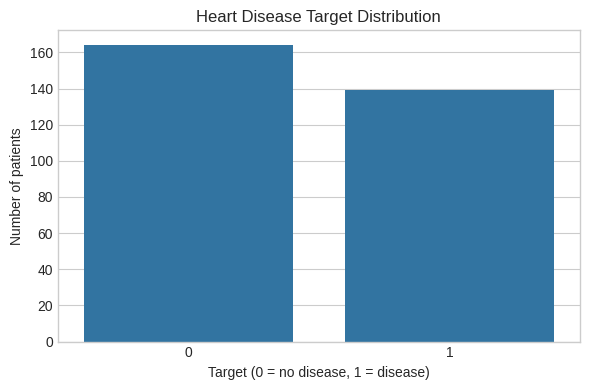

Class proportions:
target
No disease (0)    0.541254
Disease (1)       0.458746
Name: proportion, dtype: float64


In [28]:
# Plot target distribution and print class proportions
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df_encoded, x="target", ax=ax)
ax.set(title="Heart Disease Target Distribution", xlabel="Target (0 = no disease, 1 = disease)", ylabel="Number of patients")
plt.tight_layout()
plt.show()

print("Class proportions:")
print(df_encoded["target"].value_counts(normalize=True).sort_index().rename(index={0: "No disease (0)", 1: "Disease (1)"}))


### 2.4. Feature Distributions

**Your task:** Plot the distribution (histogram, with a KDE overlay if you like) of the continuous features: `age`, `trestbps`, `chol`, `thalach`, `oldpeak`. A grid of subplots (as in the diabetes lab) is a clean way to show all five at once.


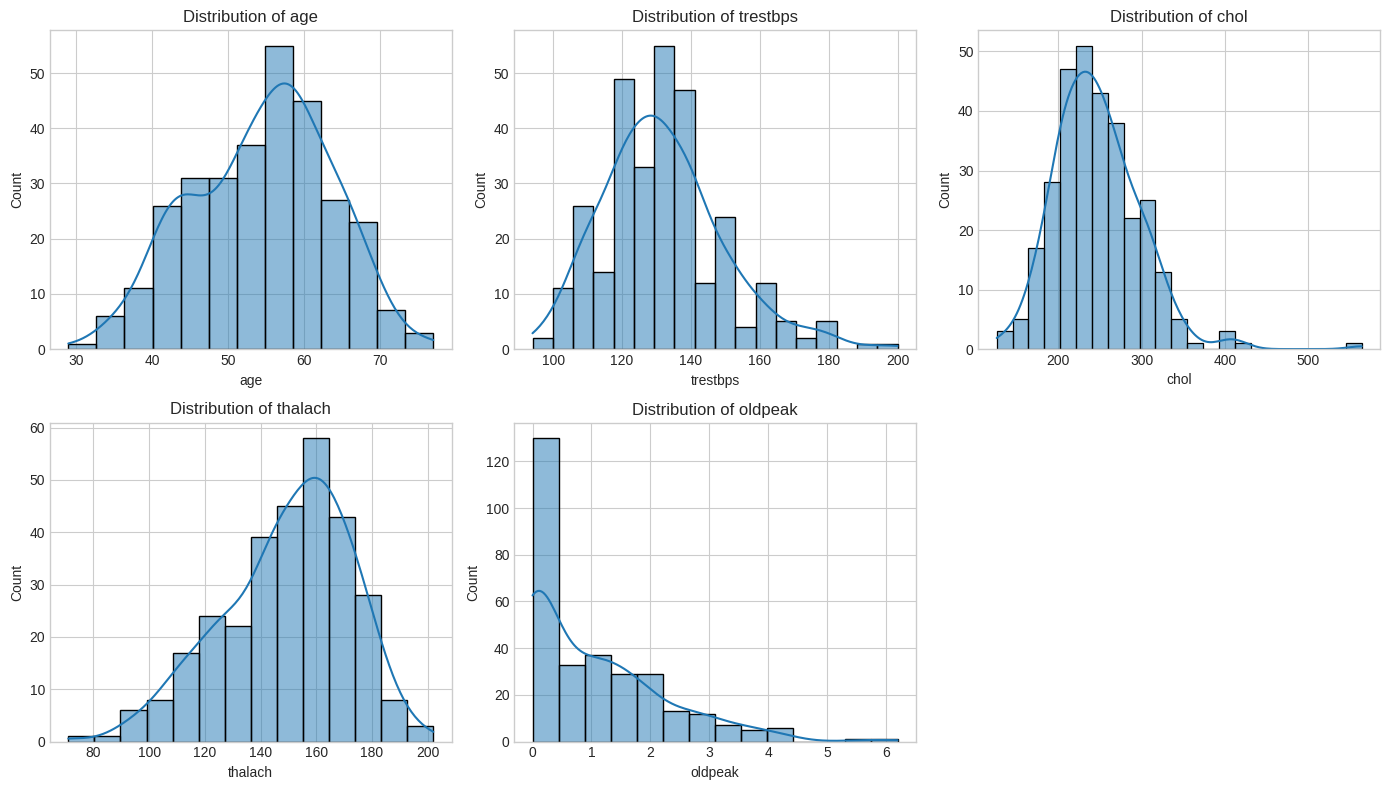

In [29]:
# Histograms for continuous features
continuous_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, continuous_features):
    sns.histplot(df_encoded[col], kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()


### 2.5. Outliers

**Your task:** Produce boxplots of the same continuous features to check for outliers. As in the diabetes lab, don't automatically drop anything — a few outliers may be clinically genuine (e.g. very high cholesterol). Just note where they are.


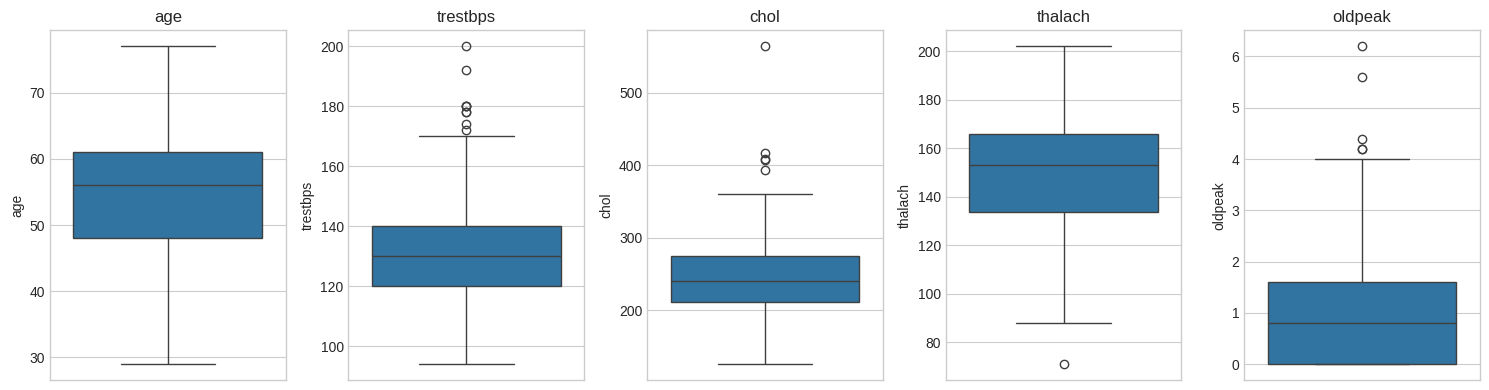

In [30]:
# Boxplots for continuous features; keep outliers unless there is a justified reason to remove them
fig, axes = plt.subplots(1, len(continuous_features), figsize=(15, 4))
for ax, col in zip(axes, continuous_features):
    sns.boxplot(y=df_encoded[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()


### 2.6. Correlation Matrix

**Your task:** Plot a correlation heatmap of `df_encoded` (all columns, post-encoding). Which features correlate most strongly with `target`?


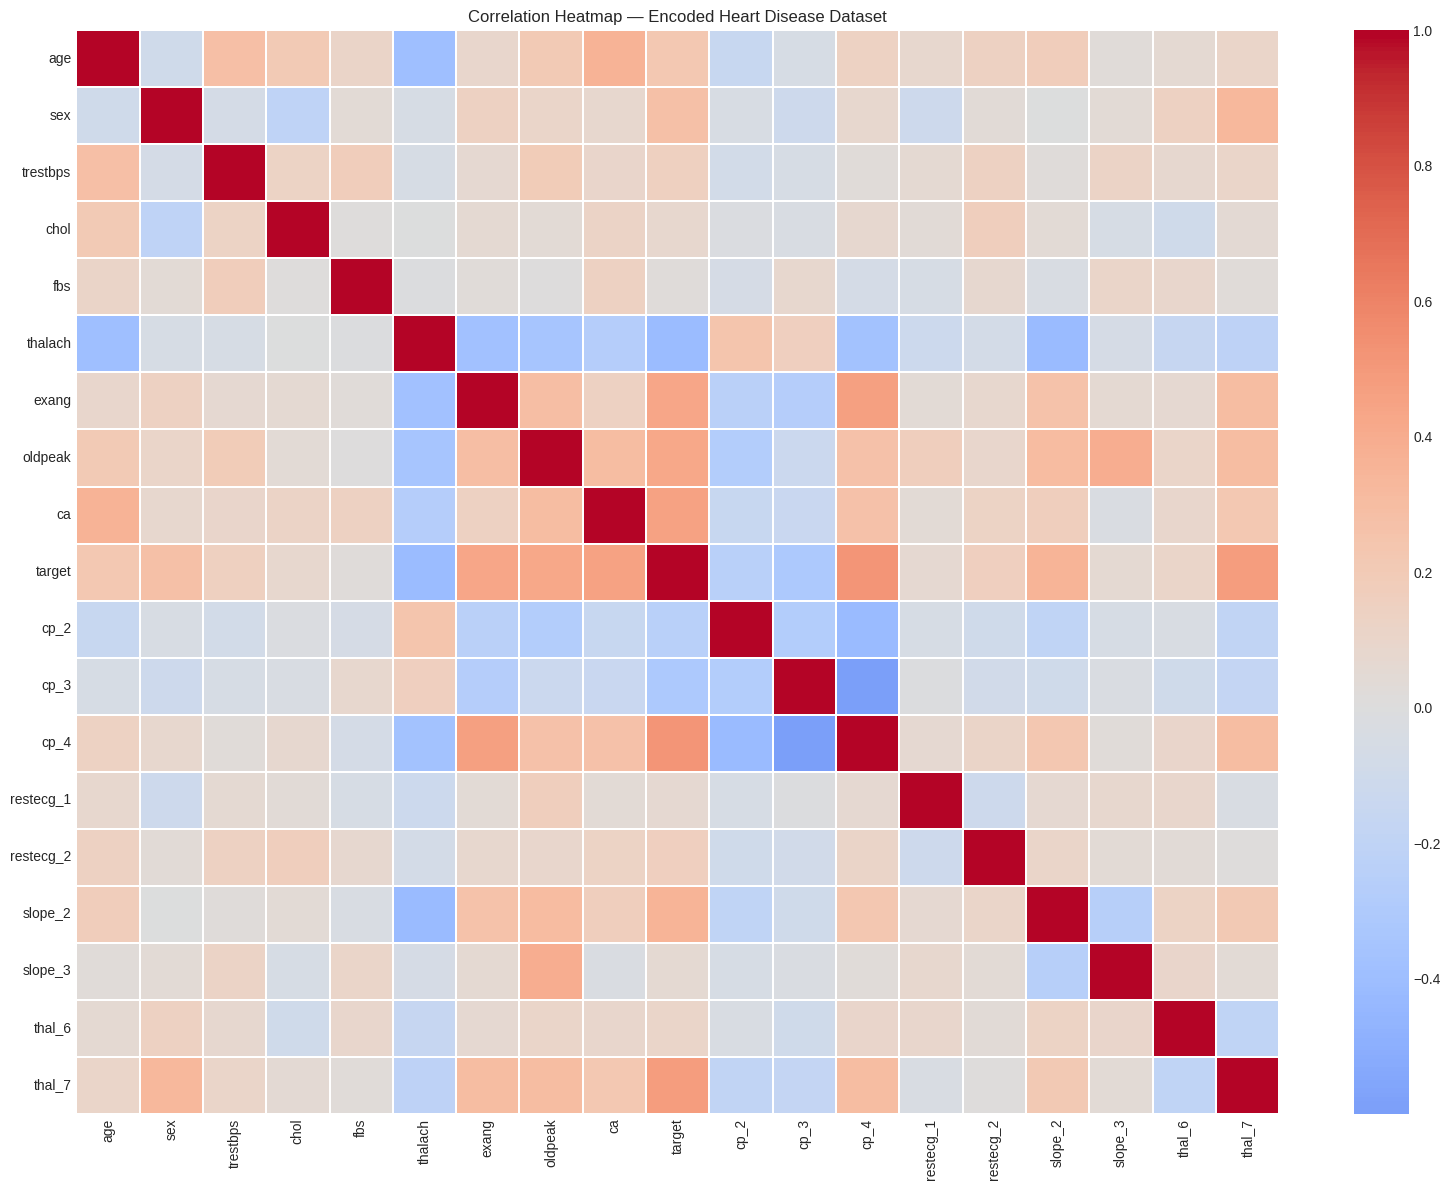

Features most positively correlated with target:
cp_4       0.516459
thal_7     0.480582
ca         0.460033
exang      0.431894
oldpeak    0.424510
slope_2    0.355709
sex        0.276816
age        0.223120
Name: target, dtype: float64

Features most negatively correlated with target:
thalach     -0.417167
cp_3        -0.315141
cp_2        -0.248683
fbs          0.025264
slope_3      0.061710
restecg_1    0.067605
chol         0.085164
thal_6       0.104864
Name: target, dtype: float64


In [31]:
# Correlation heatmap for all encoded columns
plt.figure(figsize=(16, 12))
corr = df_encoded.corr(numeric_only=True)
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.2)
plt.title("Correlation Heatmap — Encoded Heart Disease Dataset")
plt.tight_layout()
plt.show()

print("Features most positively correlated with target:")
print(corr["target"].drop("target").sort_values(ascending=False).head(8))
print("\nFeatures most negatively correlated with target:")
print(corr["target"].drop("target").sort_values().head(8))


## 3. Data Preparation for Modeling

**Your task:**
1. Split `df_encoded` into `X` (all columns except `target`) and `y` (`target`).
2. Split `X` and `y` into training and test sets (80/20), stratified on `y`, same random_state convention as the diabetes lab (`random_state=42`) so results are reproducible.
3. Scale the features with `StandardScaler` — remember: **fit only on the training data**, then transform both train and test, to avoid leaking test-set information.


In [32]:
# Separate features and target
X = df_encoded.drop(columns="target")
y = df_encoded["target"]

# Stratified split preserves the target class proportions in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Training class proportions:")
print(y_train.value_counts(normalize=True).sort_index())
print("Test class proportions:")
print(y_test.value_counts(normalize=True).sort_index())


X_train: (242, 18) | X_test: (61, 18)
Training class proportions:
target
0    0.541322
1    0.458678
Name: proportion, dtype: float64
Test class proportions:
target
0    0.540984
1    0.459016
Name: proportion, dtype: float64


In [33]:
# Fit scaler only on training data to prevent test-set leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)


Scaled training shape: (242, 18)
Scaled test shape: (61, 18)


## 4. Model Training and Standard Evaluation

Same model family as the diabetes lab — logistic regression.

**Your task:**
1. Train a `LogisticRegression` model on the scaled training data.
2. Print the standardized coefficients alongside their feature names, sorted, so you can see which features matter most (same as the diabetes lab's feature-importance step).


In [34]:
# Train logistic regression
model = LogisticRegression(max_iter=2000, random_state=42)
model.fit(X_train_scaled, y_train)

# Inspect standardized model coefficients
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": model.coef_[0]
}).sort_values("coefficient", ascending=False)

print(coef_df.to_string(index=False))


  feature  coefficient
       ca     1.153034
     cp_4     0.869874
      sex     0.737149
   thal_7     0.680931
  slope_2     0.598590
 trestbps     0.353672
     cp_2     0.340218
    exang     0.272919
     chol     0.201367
restecg_2     0.198869
  oldpeak     0.192704
  slope_3     0.074526
     cp_3     0.064135
   thal_6     0.018031
      age    -0.064349
      fbs    -0.089844
restecg_1    -0.131138
  thalach    -0.357175


**Your task:** Using the default 0.5 threshold:
1. Compute predictions (`y_pred`) and predicted probabilities (`y_pred_proba`) on the test set.
2. Print accuracy.
3. Plot a confusion matrix.
4. Print a full classification report.
5. Plot the ROC curve and print the AUC score.


In [35]:
# Default decision threshold = 0.5
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
y_pred = (y_pred_proba >= 0.5).astype(int)

print(f"Accuracy at threshold 0.50: {accuracy_score(y_test, y_pred):.3f}")


Accuracy at threshold 0.50: 0.820


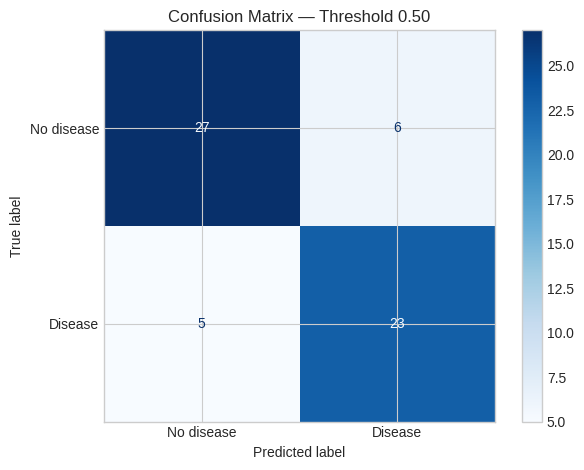

In [36]:
# Confusion matrix at the default threshold
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No disease", "Disease"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Threshold 0.50")
plt.tight_layout()
plt.show()


In [37]:
# Classification report at the default threshold
print(classification_report(
    y_test, y_pred, labels=[0, 1],
    target_names=["No disease", "Disease"], zero_division=0
))


              precision    recall  f1-score   support

  No disease       0.84      0.82      0.83        33
     Disease       0.79      0.82      0.81        28

    accuracy                           0.82        61
   macro avg       0.82      0.82      0.82        61
weighted avg       0.82      0.82      0.82        61



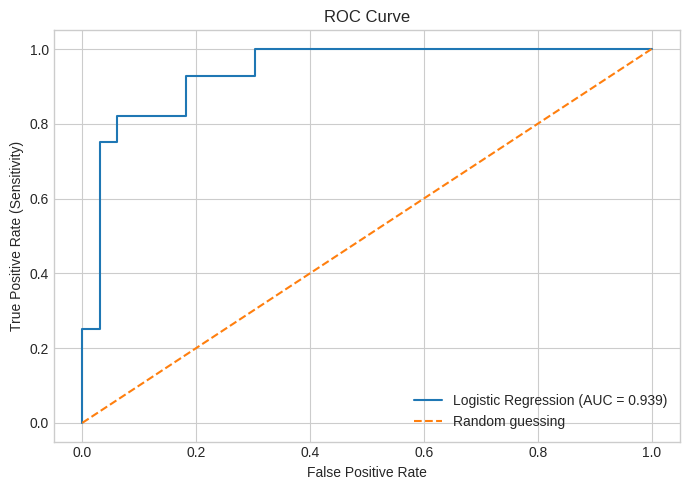

ROC-AUC: 0.939


In [38]:
# ROC curve and AUC
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_proba)
auc_score = roc_auc_score(y_test, y_pred_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()
print(f"ROC-AUC: {auc_score:.3f}")


## 5. From "Model" to "Clinical Decision Support Tool": Choosing the Alert Threshold

Everything above used the default 0.5 cutoff: if the model's estimated probability of disease is above 50%, predict "disease." **That 0.5 is a modeling default, not a clinical decision.** A real CDS tool's threshold should reflect the relative cost of the two kinds of mistakes:

- **False Negative** (model says "no disease," patient actually has it): a missed referral — the patient doesn't see a cardiologist when they should.
- **False Positive** (model says "disease," patient doesn't have it): an unnecessary referral — costs clinician time, patient anxiety, and healthcare-system resources, but is far less dangerous than a miss.

In most screening contexts, missing a case is considered worse than an unnecessary referral — which argues for a **lower** threshold than 0.5 (more sensitive, more referrals, catches more true cases, but also more false alarms). Let's see this trade-off directly instead of just asserting it.

**Your task:** Using `precision_recall_curve(y_test, y_pred_proba)`, plot precision and recall against threshold, and also plot the **referral rate** (the fraction of test patients flagged) at each threshold — `(y_pred_proba >= t).mean()` for each threshold `t`.


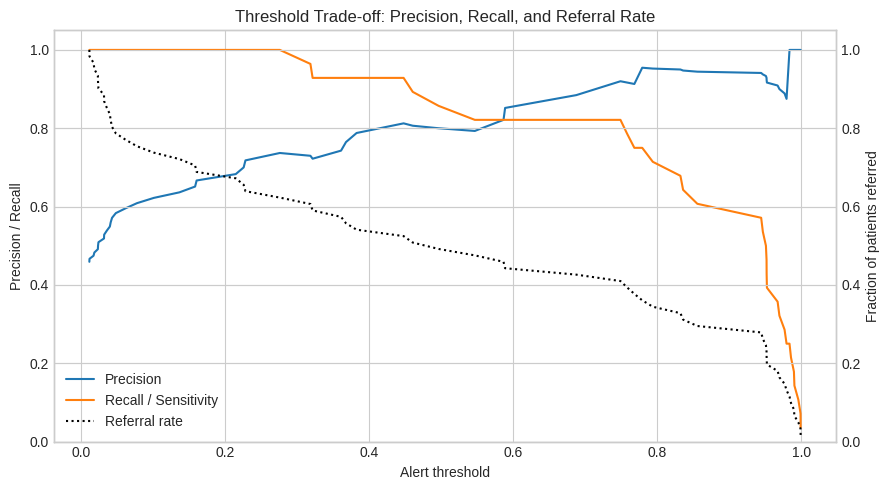

In [39]:
# Precision-recall values and referral rate across thresholds
precisions, recalls, pr_thresholds = precision_recall_curve(y_test, y_pred_proba)

# precision and recall have one more point than thresholds; align to thresholds
precision_for_thresholds = precisions[:-1]
recall_for_thresholds = recalls[:-1]
referral_rates = np.array([(y_pred_proba >= t).mean() for t in pr_thresholds])

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(pr_thresholds, precision_for_thresholds, label="Precision")
ax1.plot(pr_thresholds, recall_for_thresholds, label="Recall / Sensitivity")
ax1.set_xlabel("Alert threshold")
ax1.set_ylabel("Precision / Recall")
ax1.set_ylim(0, 1.05)

ax2 = ax1.twinx()
ax2.plot(pr_thresholds, referral_rates, color="black", linestyle=":", label="Referral rate")
ax2.set_ylabel("Fraction of patients referred")
ax2.set_ylim(0, 1.05)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")
ax1.set_title("Threshold Trade-off: Precision, Recall, and Referral Rate")
plt.tight_layout()
plt.show()


### Your task

Your clinic estimates that **missing a heart-disease case costs roughly 5 times as much** (in downstream complications, worse outcomes, potential liability) **as one unnecessary cardiology referral** (clinician time, patient inconvenience).

Using the plot above:

1. Pick a threshold that reflects this 5:1 cost ratio — you don't need a precise optimization, a reasoned choice from the chart is fine (hint: a threshold that favors recall over precision, since misses are costlier).
2. Recompute the confusion matrix and classification report at your chosen threshold using the cell below.
3. In a markdown cell, write 3–4 sentences: what threshold did you pick, what happened to sensitivity and the referral rate compared to the default, and what would you tell the clinic about the trade-off you made?


In [40]:
# A lower threshold favors sensitivity because missed cases are estimated to be 5x costlier.
my_threshold = 0.30

y_pred_threshold = (y_pred_proba >= my_threshold).astype(int)
cm_threshold = confusion_matrix(y_test, y_pred_threshold, labels=[0, 1])

print(f"Chosen threshold: {my_threshold:.2f}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_threshold):.3f}")
print(f"Referral rate: {y_pred_threshold.mean():.1%}")
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(cm_threshold)
print("\nClassification report:")
print(classification_report(
    y_test, y_pred_threshold, labels=[0, 1],
    target_names=["No disease", "Disease"], zero_division=0
))


Chosen threshold: 0.30
Accuracy: 0.820
Referral rate: 60.7%

Confusion matrix (rows = actual, columns = predicted):
[[23 10]
 [ 1 27]]

Classification report:
              precision    recall  f1-score   support

  No disease       0.96      0.70      0.81        33
     Disease       0.73      0.96      0.83        28

    accuracy                           0.82        61
   macro avg       0.84      0.83      0.82        61
weighted avg       0.85      0.82      0.82        61



I chose a threshold of **0.30** because missing a heart-disease case is considered five times more costly than making an unnecessary referral. Compared with the default threshold of 0.50, this lower cutoff should increase sensitivity and the number of patients referred, although it may also increase false positives. The clinic would need to balance catching more possible cases against referral capacity and alert fatigue. This is a teaching model and the threshold must be clinically validated before any real-world use.


## 6. Seeing the Alert in Action: Three Patients at the Clinic

Let's simulate three patients arriving for a routine checkup and see what the CDS tool would say — first at the default 0.5 threshold, then at your chosen threshold from Section 5.

The cell below already defines three patient profiles for you (a data-entry task isn't the point of this exercise) — column order matches `X.columns` automatically.

**Your task:** Scale the sample patients with your already-fitted scaler, get predicted probabilities from your trained model, and build a small results table showing each patient's probability and alert decision at (a) the default 0.5 threshold and (b) your chosen threshold from Section 5.


In [41]:
sample_patients = pd.DataFrame([
    {  # Profile A: several risk factors present
        "age": 62, "sex": 1, "trestbps": 152, "chol": 275, "fbs": 0,
        "thalach": 118, "exang": 1, "oldpeak": 2.4, "ca": 2,
        "cp_2": 0, "cp_3": 0, "cp_4": 1,
        "restecg_1": 0, "restecg_2": 1,
        "slope_2": 1, "slope_3": 0,
        "thal_6": 0, "thal_7": 1,
    },
    {  # Profile B: mostly low risk factors
        "age": 41, "sex": 0, "trestbps": 118, "chol": 190, "fbs": 0,
        "thalach": 172, "exang": 0, "oldpeak": 0.2, "ca": 0,
        "cp_2": 1, "cp_3": 0, "cp_4": 0,
        "restecg_1": 0, "restecg_2": 0,
        "slope_2": 0, "slope_3": 0,
        "thal_6": 0, "thal_7": 0,
    },
    {  # Profile C: borderline / mixed signals
        "age": 55, "sex": 1, "trestbps": 130, "chol": 233, "fbs": 1,
        "thalach": 150, "exang": 0, "oldpeak": 1.0, "ca": 0,
        "cp_2": 0, "cp_3": 1, "cp_4": 0,
        "restecg_1": 0, "restecg_2": 0,
        "slope_2": 1, "slope_3": 0,
        "thal_6": 0, "thal_7": 0,
    },
])[X.columns]  # ensure column order matches training data


In [42]:
# Align sample columns to the training data and scale using the already-fitted scaler
sample_patients_scaled = scaler.transform(sample_patients[X.columns])

# Estimated probability of disease for each profile
sample_probabilities = model.predict_proba(sample_patients_scaled)[:, 1]

results = pd.DataFrame({
    "Patient": ["Profile A", "Profile B", "Profile C"],
    "Predicted Probability": sample_probabilities,
    "Alert at 0.5 (default)": sample_probabilities >= 0.5,
    f"Alert at {my_threshold:.2f} threshold": sample_probabilities >= my_threshold
})
results["Predicted Probability"] = results["Predicted Probability"].map(lambda p: f"{p:.1%}")
print(results.to_string(index=False))


  Patient Predicted Probability  Alert at 0.5 (default)  Alert at 0.30 threshold
Profile A                 99.8%                    True                     True
Profile B                  1.2%                   False                    False
Profile C                 13.4%                   False                    False


Check: does any patient's alert *change* between the default threshold and your chosen one? If so, that's exactly the kind of patient where the threshold decision matters most in practice.


## 7. Discussion Questions (for lab writeup or in-class discussion)

These connect this lab to next week's Unit III material on risk and human-centered AI — no code needed, just written responses.

1. If you lower the alert threshold to catch more true cases, referrals go up. At what point would you worry about **alert fatigue** — clinicians starting to ignore the tool because it fires too often?
2. Who should be responsible for deciding this threshold: the AI developer, the hospital administration, the treating clinician, or a clinical guidelines committee? Why?
3. This model was trained on 303 patients from one hospital in Cleveland in the 1980s. What could go wrong if it's deployed, unmodified, at a hospital in a different country with a different patient population — this is a preview of *dataset shift*, coming up in Unit III.
4. The interface only needs to show "refer" or "don't refer." What else should a clinician see alongside that alert (e.g., the probability, the top contributing factors, a confidence indicator) to trust and use it well?


## Discussion Question Answers

1. **Alert fatigue:** I would worry about alert fatigue when too many patients are flagged and clinicians start ignoring alerts. The threshold should be tested against referral capacity and reviewed with clinicians.
2. **Who chooses the threshold?** A clinical guidelines committee should lead the decision with input from treating clinicians, hospital administration, and AI developers. This combines clinical safety, workflow needs, and technical evidence.
3. **Dataset shift:** Patients in another country or a modern hospital may differ in risk factors, testing, and disease patterns. The model could become less accurate, so it should be externally validated and monitored before use.
4. **What the clinician should see:** The interface should show the estimated probability, the threshold used, key factors contributing to the alert, and a clear reminder that this is decision support rather than a diagnosis. Clinicians should retain final responsibility for care decisions.


## 8. Conclusion & Next Steps

By completing this lab yourself, you've practiced:

1. Loading and cleaning real clinical data with genuinely missing values (not disguised as zeros).
2. Encoding categorical clinical codes correctly instead of treating them as ordinary numbers.
3. Training and evaluating a logistic regression model the same way as last week — but this time without a worked example to copy from.
4. Treating the **alert threshold as a clinical policy decision**, tied to the relative cost of a missed diagnosis vs. an unnecessary referral — not a modeling default.
5. Applying your trained model to individual patients, and connecting the results to human-centered questions (alert fatigue, accountability, dataset shift) that the course returns to shortly.

**Next lab:** explainability (SHAP / feature contributions) and calibration — so that instead of just an alert, the tool can also say *why* it's flagging a patient, and how much to trust its stated probability.
